# MSH chain on a 2D substrate: spin ramp, exact and sparse time evolution

**Goal.** Reference time evolution for `msh_substrate_td_tn.ipynb` (TDVP on the quantics MPO), at sizes where it can be checked
against exact evolution, before the scaling scan of the ramp.

**Protocol.** The chain spins rotate from $\hat z$ (topological) to the in-plane antiferromagnet (trivial), from both chain ends
inwards, one site after the other (`Ramp` in `substrate_model.py`): site $k$ from the nearer end starts at $t = 0.1\,k\,T_{\rm rot}$ and
turns with $f = \sin^2(\pi\tau/2)$ over $T_{\rm rot}$, $\mathbf S = (0, \sin\theta, \cos\theta)$, $\theta = (-1)^{i_x}\tfrac\pi2 f$, until only the middle
4 sites are along $\hat z$. The topological segment shrinks from $\ell$ to 4 sites and the two Majoranas are pushed together and fuse.
The ramp lasts $T = (0.1\,((\ell - 4)/2 - 1) + 1)\,T_{\rm rot}$.

**State and readouts.** The fermion mode $\psi_f$ of $H(0)$ (the $+E$ member of the zero-mode pair) is evolved with
$i\partial_t\psi = H(t)\psi$. Recorded: $\Delta Q(t) = \langle\psi|\tau_z|\psi\rangle$ about 130 times over the ramp, and at the end the weights
$p_\pm = |\langle\phi_\pm(T)|\psi(T)\rangle|^2$ on the two states $\phi_\pm$ of the final pair (energies $\pm E_f(T)$) and the **leak**
$1 - p_+ - p_-$, the weight that left the pair (bulk excitation).

**Two parameter points, two speeds each** (from a first scan of the leak):

| point | $\mu$, $\Delta$, $J$, $\ell$ | fast $T_{\rm rot}$ | slow $T_{\rm rot}$ | sizes |
|---|---|---|---|---|
| benchmark (`bench`) | $-7$, 2.4, 5.8, 12 | 10 ($T = 13$) | 100 ($T = 130$) | $16\times4$, $32\times8$, $32\times32$ |
| leaking (`leak`) | $-3$, 0.6, 3, 64 | 100 ($T = 390$) | 1600 ($T = 6240$) | $128\times2$, $128\times8$, $128\times32$ |

**Time step.** All methods use the midpoint rule $\psi \leftarrow e^{-i\,\delta t\,H(t+\delta t/2)}\psi$ with $\delta t = 0.1$, the rule of
TensorBinding's `evolve_with_tdvp_timedep`; at equal $\delta t$ the methods differ only by how they apply the exponential.

**Code.** Model and ramp from `substrate_model.py`. Results: `td_py_runs.csv`, `td_py_dQ.csv`, `td_py_dense.csv`, `td_py_dt.csv`,
`td_py_large.csv`, `td_py_large_dQ.csv`, `td_py_step2048.csv`, `td_py_step_idle.csv` (committed) and `data/td_py_psi_*.npz` (initial and final states, read by the TN notebook; not committed).

**Contents**
1. Setup
2. The ramp and the spectrum along it
3. Exact (dense) against the sparse reference
4. Time step
5. Sparse reference at the small sizes
6. Majorana readout
7. Sparse reference on large substrates
8. Summary


## 1. Setup

In [ ]:
import os, time
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[v] = "1"        # single thread per process (set before NumPy is imported)
import numpy as np
import scipy.linalg as la
from scipy.sparse.linalg import eigsh, expm_multiply
from multiprocessing import Pool
import matplotlib.pyplot as plt
from substrate_model import *  # ham, PC, Ramp, ramp_f, ramp_duration, snap_every, ... (substrate_model.py)

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
DT = 0.1                      # time step of every method
NPROC = 8                     # independent runs in parallel, one thread each
POINTS = {
    "bench": dict(P={}, ell=12, rots=(10.0, 100.0), sizes=[(4, 2), (5, 3), (5, 5)]),
    "leak":  dict(P=PC, ell=64, rots=(100.0, 1600.0), sizes=[(7, 1), (7, 3), (7, 5)]),
}

def ramp(point, Lx, Ly, rot_T):
    p = POINTS[point]
    return Ramp(Lx, Ly, p["ell"], rot_T, **p["P"])

def pair(H, k=4):
    "k eigenpairs closest to zero (shift-invert), sorted by |E|."
    E, V = eigsh(H, k=k, sigma=0, which="LM"); o = np.argsort(np.abs(E))
    return E[o], V[:, o]

def dQ_of(psi):
    "⟨ψ|τ_z|ψ⟩: particle (c↑, c↓) minus hole (c†↓, −c†↑) weight."
    v = psi.reshape(-1, 4)
    return np.sum(np.abs(v[:, :2])**2) - np.sum(np.abs(v[:, 2:])**2)

def initial_state(R):
    "ψ_f: the +E member of the zero-mode pair of H(0), and E_f(0)."
    E, V = pair(R.H(0.0)); ip = np.argmax(E[:2])
    return E[ip], V[:, ip].copy()

def evolve(R, psi, dt=DT, method="sparse", t_end=None):
    """Midpoint rule ψ ← exp(−i dt H(t + dt/2)) ψ from 0 to t_end (default: the end of the ramp), by expm_multiply ("sparse") or
    by the eigendecomposition of the dense H ("dense"). ΔQ is recorded every snap_every(R.T, dt) steps and at the end.
    Returns ψ, the recorded times, ΔQ there, and the wall time."""
    n = int(round((R.T if t_end is None else t_end) / dt)); every = snap_every(R.T, dt)
    ts, dQ = [0.0], [dQ_of(psi)]
    t_ = time.perf_counter()
    for s in range(n):
        Hm = R.H((s + 0.5) * dt)
        if method == "sparse":
            psi = expm_multiply(-1j * dt * Hm, psi)
        else:
            E, V = la.eigh(Hm.toarray())
            psi = V @ (np.exp(-1j * dt * E) * (V.conj().T @ psi))
        if (s + 1) % every == 0 or s + 1 == n:
            ts.append((s + 1) * dt); dQ.append(dQ_of(psi))
    return psi, np.array(ts), np.array(dQ), time.perf_counter() - t_

def final_readout(R, psi):
    "Weights of ψ on the +E and −E states of the final pair, the leak 1 − p₊ − p₋, E_f(T) and ΔQ of the +E state."
    E, V = pair(R.H(R.T)); ip = np.argmax(E[:2]); im = 1 - ip
    pp, pm = abs(np.vdot(V[:, ip], psi))**2, abs(np.vdot(V[:, im], psi))**2
    return dict(E_fT=E[ip], dQ_plus_T=dQ_of(V[:, ip]), p_plus=pp, p_minus=pm, leak=1 - pp - pm)

def write_csv(path, rows, cols):
    with open(path, "w") as f:
        f.write(",".join(cols) + "\n")
        for r in rows:
            f.write(",".join(str(r[c]) for c in cols) + "\n")

def read_csv(path):
    return np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)

## 2. The ramp and the spectrum along it

Left: the rotation fraction $f$ of every chain site against time at the leaking point ($\ell = 64$). Middle and right: the six
levels closest to zero along the ramp (time in units of $T_{\rm rot}$; the spectrum of $H(t)$ depends on $t/T_{\rm rot}$ only), at
$32\times8$ (benchmark) and $128\times8$ (leaking), and the energy of the pair state followed continuously from $\psi_f$ (at each of
301 times the pair eigenvector with the larger overlap with the previous one). The splitting of the pair oscillates with the length of
the topological segment and changes sign several times; an adiabatic evolution follows these crossings, which the parity of the
pair protects, so $\psi_f$ can end in either member of the final pair. The minimum of the third level is the gap that sets how slow
the ramp must be.

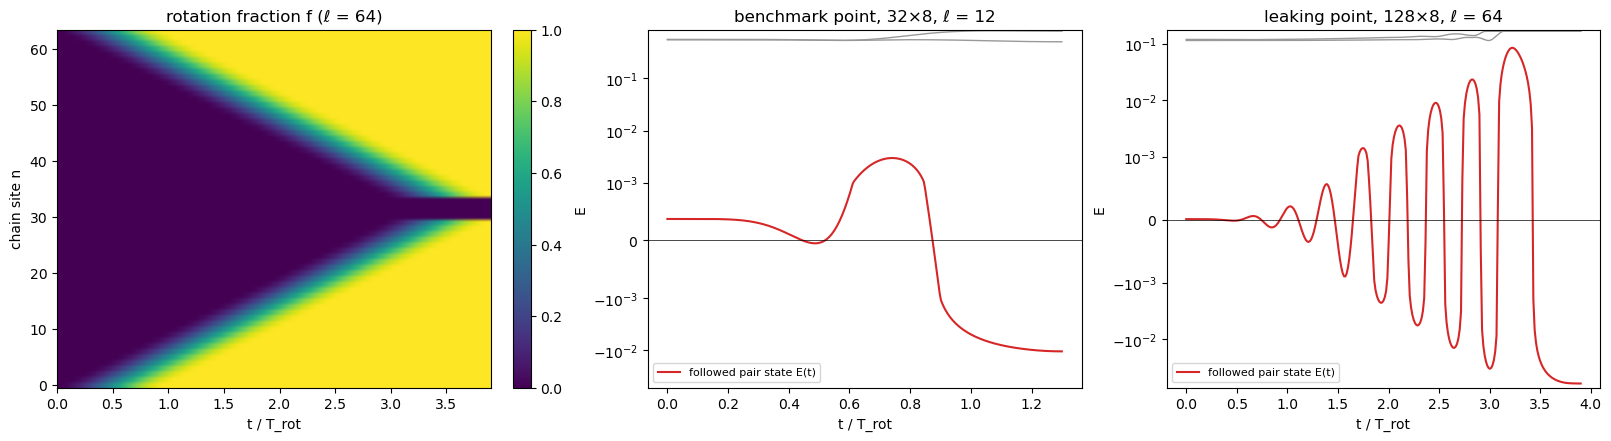

bench: min gap 0.5068 at t/T_rot = 1.30; followed state: 3 sign changes, E(T) = -1.0457e-02 (−E member of the final pair)
leak: min gap 0.1147 at t/T_rot = 2.99; followed state: 17 sign changes, E(T) = -6.0991e-02 (−E member of the final pair)


In [2]:
def track(point, Lx, Ly, n=301):
    R = ramp(point, Lx, Ly, 1.0)
    ts = np.linspace(0, R.T, n)
    E, V = pair(R.H(0.0), 6); w = V[:, np.argmax(E[:2])]
    levels, E_tr = [], []
    for t in ts:
        E, V = pair(R.H(t), 6)
        j = np.argmax(np.abs(V[:, :2].conj().T @ w)); w = V[:, j]
        levels.append(np.abs(E)); E_tr.append(E[j])
    return ts, np.array(levels), np.array(E_tr)

with Pool(2) as pool:
    tracks = dict(zip(("bench", "leak"), pool.starmap(track, [("bench", 5, 3), ("leak", 7, 3)])))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), constrained_layout=True)
R = ramp("leak", 7, 3, 1.0); tt = np.linspace(0, R.T, 400)
im = ax[0].imshow([[ramp_f(t, n, 64, 1.0) for t in tt] for n in range(64)], aspect="auto", origin="lower",
                  extent=[0, R.T, -0.5, 63.5], cmap="viridis")
ax[0].set_xlabel("t / T_rot"); ax[0].set_ylabel("chain site n"); ax[0].set_title("rotation fraction f (ℓ = 64)")
fig.colorbar(im, ax=ax[0])
for a, (point, title) in zip(ax[1:], (("bench", "benchmark point, 32×8, ℓ = 12"), ("leak", "leaking point, 128×8, ℓ = 64"))):
    ts, lev, Etr = tracks[point]
    for k in range(2, 6, 2):
        a.plot(ts, lev[:, k], color="0.6", lw=1)
    a.plot(ts, Etr, color="tab:red", lw=1.5, label="followed pair state E(t)")
    a.axhline(0, color="k", lw=0.5); a.set_xlabel("t / T_rot"); a.set_ylabel("E"); a.set_title(title); a.legend(fontsize=8)
    a.set_yscale("symlog", linthresh=1e-3)
plt.show()
for point, (ts, lev, Etr) in tracks.items():
    sign_changes = int(np.sum(np.diff(np.sign(Etr)) != 0))
    print(f"{point}: min gap {lev[:, 2].min():.4f} at t/T_rot = {ts[np.argmin(lev[:, 2])]:.2f}; followed state: {sign_changes} sign "
          f"changes, E(T) = {Etr[-1]:+.4e} ({'+' if Etr[-1] > 0 else '−'}E member of the final pair)")

## 3. Exact (dense) against the sparse reference

The same midpoint rule two ways: the dense propagator from the eigendecomposition of $H(t+\delta t/2)$ (exact for that rule) and
SciPy's `expm_multiply` on the sparse matrix (a truncated Taylor series with scaling, to double precision). This sparse-matrix evolution is the reference of both notebooks ("sparse" in the tables):
it needs only products of $H$ with vectors, so a step costs $\propto N$. It is not a Krylov-subspace method; the only Krylov solver in
these notebooks is the local one inside TDVP. Where the dense matrix
is small enough: the benchmark point at $16\times4$ and $32\times8$ (both speeds), and the leaking point at $128\times2$ ($D = 1024$,
0.4 s per dense step) for $T_{\rm rot} = 100$, and for $T_{\rm rot} = 1600$ up to $t = 390$ (the full ramp would take 7 hours). Both from the
same $\psi_f$, each case in its own process. Results to `td_py_dense.csv` (`RUN_DENSE = False` only loads it).

In [ ]:
RUN_DENSE = False   # results are in the CSV files; True recomputes
dense_file = "td_py_dense.csv"
DENSE_CASES = [("bench", 4, 2, 10.0, None), ("bench", 4, 2, 100.0, None), ("bench", 5, 3, 10.0, None), ("bench", 5, 3, 100.0, None),
               ("leak", 7, 1, 100.0, None), ("leak", 7, 1, 1600.0, 390.0)]
dense_cols = ["point", "Lx", "Ly", "rot_T", "t_end", "D", "diff_psi", "max_diff_dQ", "dQ_end", "s_dense", "s_sparse"]

def dense_vs_sparse(point, Lx, Ly, rot, t_end):
    R = ramp(point, Lx, Ly, rot); _, psi0 = initial_state(R)
    pd, _, qd, sd = evolve(R, psi0, method="dense", t_end=t_end)
    pk, _, qk, sk = evolve(R, psi0, method="sparse", t_end=t_end)
    return dict(point=point, Lx=Lx, Ly=Ly, rot_T=rot, t_end=R.T if t_end is None else t_end, D=4 * R.N,
                diff_psi=np.linalg.norm(pk - pd), max_diff_dQ=np.abs(qk - qd).max(), dQ_end=qk[-1], s_dense=sd, s_sparse=sk)

if RUN_DENSE or not os.path.isfile(dense_file):
    with Pool(NPROC) as pool:
        write_csv(dense_file, pool.starmap(dense_vs_sparse, DENSE_CASES), dense_cols)
dn = read_csv(dense_file)
print(f"{'point':>6s} {'substrate':>9s} {'D':>5s} {'T_rot':>6s} {'t_end':>6s} | {'‖ψ_K − ψ_dense‖':>15s} {'max|ΔQ_K − ΔQ_d|':>17s} "
      f"{'ΔQ(t_end)':>11s} | {'dense':>7s} {'sparse':>7s}")
for r in dn:
    print(f"{r['point']:>6s} {2**r['Lx']:>4d}×{2**r['Ly']:<4d} {r['D']:5d} {r['rot_T']:6.0f} {r['t_end']:6.0f} | {r['diff_psi']:15.1e} "
          f"{r['max_diff_dQ']:17.1e} {r['dQ_end']:+11.6f} | {r['s_dense']:6.0f}s {r['s_sparse']:6.1f}s")

 point substrate     D  T_rot  t_end | ‖ψ_K − ψ_dense‖  max|ΔQ_K − ΔQ_d|   ΔQ(t_end) |   dense  sparse
 bench   16×4      256     10     13 |         3.2e-13           6.7e-14   -0.007189 |      1s    0.1s
 bench   16×4      256    100    130 |         9.7e-13           1.0e-13   -0.107206 |     11s    1.0s
 bench   32×8     1024     10     13 |         6.0e-13           7.1e-14   +0.001621 |     51s    0.1s
 bench   32×8     1024    100    130 |         1.2e-12           8.6e-14   -0.095388 |    583s    1.5s
  leak  128×2     1024    100    390 |         4.6e-12           1.2e-12   +0.014587 |   1681s    4.2s
  leak  128×2     1024   1600    390 |         1.2e-12           1.1e-13   -0.001017 |   1659s    4.3s


## 4. Time step

The midpoint rule is second order: its error in $\psi(T)$ should drop four times when $\delta t$ is halved. The sparse reference at
$\delta t = 0.1, 0.05, 0.025$ on the smallest size of each point, both speeds; differences of the final state and of the readouts from
$\delta t = 0.025$. This is the time-discretization error that every method of the two notebooks shares at $\delta t = 0.1$. Results to
`td_py_dt.csv`.

In [ ]:
RUN_DT = False   # results are in the CSV files; True recomputes
dt_file = "td_py_dt.csv"
DTS = (0.1, 0.05, 0.025)
DT_CASES = [(pt, *POINTS[pt]["sizes"][0], rot) for pt in POINTS for rot in POINTS[pt]["rots"]]
dt_cols = ["point", "Lx", "Ly", "rot_T", "dt", "diff_psi", "dQ_T", "leak", "p_plus", "p_minus", "secs"]

def dt_check(point, Lx, Ly, rot):
    R = ramp(point, Lx, Ly, rot); _, psi0 = initial_state(R)
    out = {dt: evolve(R, psi0, dt=dt) for dt in DTS}
    ref = out[DTS[-1]][0]
    return [dict(point=point, Lx=Lx, Ly=Ly, rot_T=rot, dt=dt, diff_psi=np.linalg.norm(psi - ref), dQ_T=q[-1], secs=s,
                 **{k: v for k, v in final_readout(R, psi).items() if k in ("leak", "p_plus", "p_minus")})
            for dt, (psi, _, q, s) in out.items()]

if RUN_DT or not os.path.isfile(dt_file):
    with Pool(NPROC) as pool:
        write_csv(dt_file, [r for rows in pool.starmap(dt_check, DT_CASES) for r in rows], dt_cols)
dtr = read_csv(dt_file)
print(f"{'point':>6s} {'substrate':>9s} {'T_rot':>6s} {'dt':>6s} | {'‖ψ − ψ(0.025)‖':>14s} {'ΔQ(T)':>12s} {'leak':>10s} {'p₊':>9s} {'p₋':>9s}")
for r in dtr:
    print(f"{r['point']:>6s} {2**r['Lx']:>4d}×{2**r['Ly']:<4d} {r['rot_T']:6.0f} {r['dt']:6.3f} | {r['diff_psi']:14.1e} {r['dQ_T']:+12.7f} "
          f"{r['leak']:10.3e} {r['p_plus']:9.6f} {r['p_minus']:9.6f}")

 point substrate  T_rot     dt | ‖ψ − ψ(0.025)‖        ΔQ(T)       leak        p₊        p₋
 bench   16×4        10  0.100 |        3.0e-04   -0.0071888  5.283e-01  0.000002  0.471654
 bench   16×4        10  0.050 |        5.9e-05   -0.0071508  5.284e-01  0.000002  0.471554
 bench   16×4        10  0.025 |        0.0e+00   -0.0071415  5.285e-01  0.000002  0.471530
 bench   16×4       100  0.100 |        7.6e-07   -0.1072062  4.220e-07  0.000000  1.000000
 bench   16×4       100  0.050 |        1.5e-07   -0.1072062  4.222e-07  0.000000  1.000000
 bench   16×4       100  0.025 |        0.0e+00   -0.1072062  4.222e-07  0.000000  1.000000
  leak  128×2       100  0.100 |        8.6e-06   +0.0145865  9.220e-01  0.002179  0.075837
  leak  128×2       100  0.050 |        1.7e-06   +0.0145866  9.220e-01  0.002179  0.075837
  leak  128×2       100  0.025 |        0.0e+00   +0.0145866  9.220e-01  0.002179  0.075837
  leak  128×2      1600  0.100 |        3.7e-08   +0.6616880  1.356e-05  0.00000

## 5. Sparse reference at the small sizes

All sizes of both points at both speeds, $\delta t = 0.1$, each in its own process (8 at a time; the times per step are therefore
with 8 runs sharing the machine). Per run: $E_f(0)$, $\Delta Q(0)$, $\Delta Q(T)$, the final-pair weights $p_\pm$ and the leak, $E_f(T)$ and
$\Delta Q$ of the final $+E$ state, and the wall time. Summary to `td_py_runs.csv`, $\Delta Q(t)$ to `td_py_dQ.csv`, $\psi(0)$ and $\psi(T)$ to
`data/td_py_psi_<point>_<Lx>_<Ly>_rot<T_rot>.npz`. Runs already in `td_py_runs.csv` are skipped (`RUN_SPARSE = False` only loads).

 point substrate      D  T_rot      T |     E_f(0)       ΔQ(0)       ΔQ(T) |        p₊        p₋      leak |   E_f(T)    ΔQ₊(T) | ms/step
 bench   16×4       256     10     13 |  4.151e-04 -3.8582e-03   -0.007189 |  0.000002  0.471654  5.28e-01 |   0.0108 +0.107233 |    0.82
 bench   16×4       256    100    130 |  4.151e-04 -3.8582e-03   -0.107206 |  0.000000  1.000000  4.22e-07 |   0.0108 +0.107233 |    0.83
 bench   32×8      1024     10     13 |  3.714e-04 -3.4483e-03   +0.001621 |  0.000000  0.468295  5.32e-01 |   0.0105 +0.095482 |    1.12
 bench   32×8      1024    100    130 |  3.714e-04 -3.4483e-03   -0.095388 |  0.000000  1.000000  4.73e-07 |   0.0105 +0.095482 |    1.07
 bench   32×32     4096     10     13 |  3.712e-04 -3.4466e-03   +0.001600 |  0.000000  0.468324  5.32e-01 |   0.0105 +0.095435 |    2.02
 bench   32×32     4096    100    130 |  3.712e-04 -3.4466e-03   -0.095340 |  0.000000  1.000000  4.73e-07 |   0.0105 +0.095435 |    2.12
  leak  128×2      1024    100    

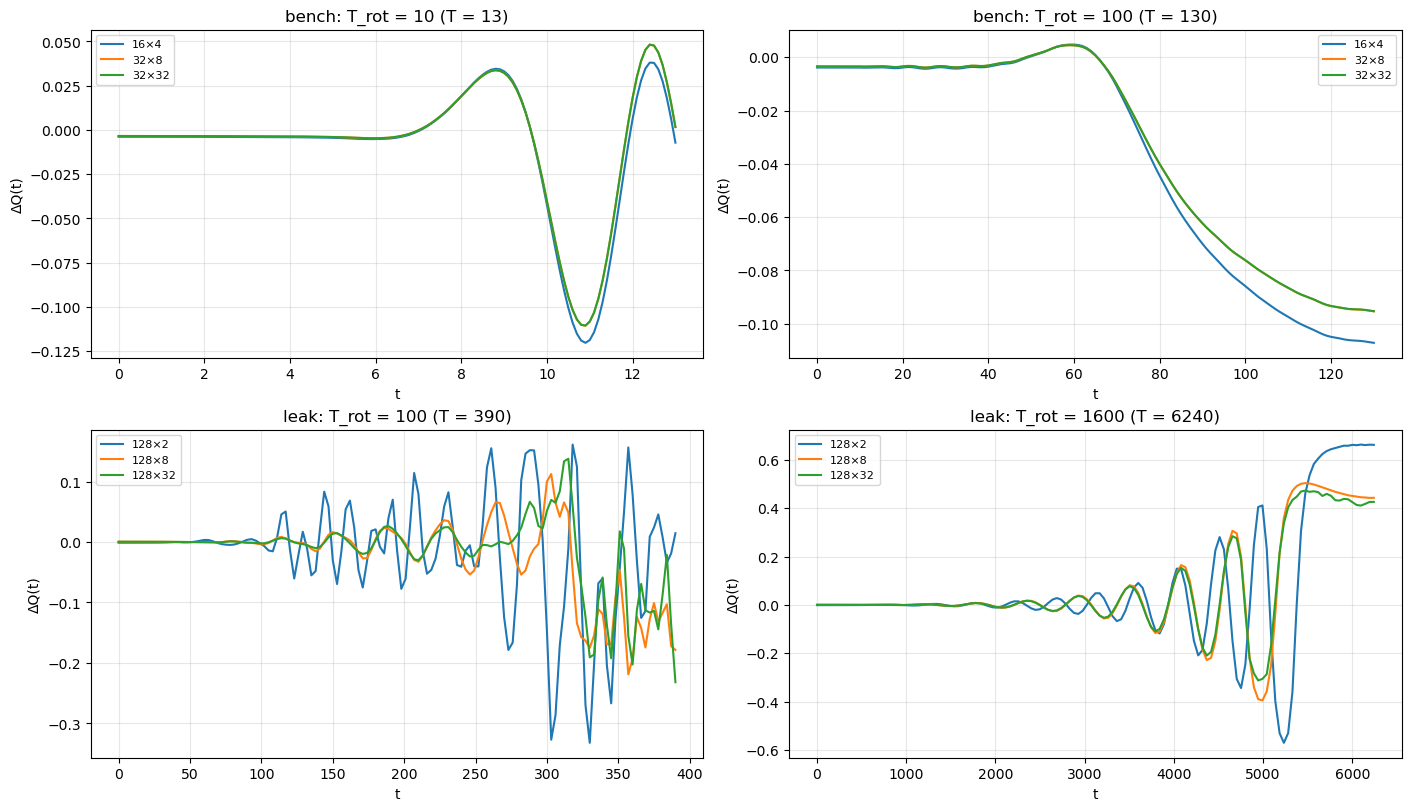

In [ ]:
RUN_SPARSE = False   # results are in the CSV files; True recomputes
runs_file, dq_file = "td_py_runs.csv", "td_py_dQ.csv"
CASES = [(pt, Lx, Ly, rot) for pt in POINTS for (Lx, Ly) in POINTS[pt]["sizes"] for rot in POINTS[pt]["rots"]]
run_cols = ["point", "Lx", "Ly", "ell", "rot_T", "T", "N", "D", "nsteps", "secs", "ms_per_step", "E_f0", "dQ0", "dQ_T",
            "p_plus", "p_minus", "leak", "E_fT", "dQ_plus_T"]
psi_file = lambda point, Lx, Ly, rot: os.path.join(DATA_DIR, f"td_py_psi_{point}_{Lx}_{Ly}_rot{rot:.0f}.npz")

def sparse_run(point, Lx, Ly, rot):
    R = ramp(point, Lx, Ly, rot); E0, psi0 = initial_state(R)
    psi, ts, dQ, secs = evolve(R, psi0)
    np.savez(psi_file(point, Lx, Ly, rot), psi0=psi0, psiT=psi, ts=ts, dQ=dQ)
    n = int(round(R.T / DT))
    row = dict(point=point, Lx=Lx, Ly=Ly, ell=R.ell, rot_T=rot, T=R.T, N=R.N, D=4 * R.N, nsteps=n, secs=secs,
               ms_per_step=1e3 * secs / n, E_f0=E0, dQ0=dQ[0], dQ_T=dQ[-1], **final_readout(R, psi))
    return row, [(point, Lx, Ly, rot, t, q) for t, q in zip(ts, dQ)]

done = set()
if os.path.isfile(runs_file):
    done = {(r["point"], int(r["Lx"]), int(r["Ly"]), float(r["rot_T"])) for r in read_csv(runs_file)}
todo = [c for c in CASES if c not in done]
if RUN_SPARSE and todo:
    with Pool(NPROC) as pool:
        res = pool.starmap(sparse_run, todo)
    new_file = not os.path.isfile(runs_file)
    with open(runs_file, "a") as f:
        if new_file: f.write(",".join(run_cols) + "\n")
        for row, _ in res: f.write(",".join(str(row[c]) for c in run_cols) + "\n")
    new_file = not os.path.isfile(dq_file)
    with open(dq_file, "a") as f:
        if new_file: f.write("point,Lx,Ly,rot_T,t,dQ\n")
        for _, series in res:
            for s in series: f.write(",".join(map(str, s)) + "\n")

kr = read_csv(runs_file)
print(f"{'point':>6s} {'substrate':>9s} {'D':>6s} {'T_rot':>6s} {'T':>6s} | {'E_f(0)':>10s} {'ΔQ(0)':>11s} {'ΔQ(T)':>11s} | "
      f"{'p₊':>9s} {'p₋':>9s} {'leak':>9s} | {'E_f(T)':>8s} {'ΔQ₊(T)':>9s} | {'ms/step':>7s}")
for r in kr:
    print(f"{r['point']:>6s} {2**r['Lx']:>4d}×{2**r['Ly']:<4d} {r['D']:6d} {r['rot_T']:6.0f} {r['T']:6.0f} | {r['E_f0']:10.3e} "
          f"{r['dQ0']:+11.4e} {r['dQ_T']:+11.6f} | {r['p_plus']:9.6f} {r['p_minus']:9.6f} {r['leak']:9.2e} | {r['E_fT']:8.4f} "
          f"{r['dQ_plus_T']:+9.6f} | {r['ms_per_step']:7.2f}")

dq = read_csv(dq_file)
fig, ax = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for i, point in enumerate(POINTS):
    for j, rot in enumerate(POINTS[point]["rots"]):
        a = ax[i, j]
        for Lx, Ly in POINTS[point]["sizes"]:
            s = dq[(dq["point"] == point) & (dq["Lx"] == Lx) & (dq["Ly"] == Ly) & (dq["rot_T"] == rot)]
            a.plot(s["t"], s["dQ"], label=f"{2**Lx}×{2**Ly}")
        R = ramp(point, *POINTS[point]["sizes"][0], rot)
        a.set_title(f"{point}: T_rot = {rot:.0f} (T = {R.T:.0f})"); a.set_xlabel("t"); a.set_ylabel("ΔQ(t)"); a.legend(fontsize=8)
        a.grid(alpha=0.3)
plt.show()

## 6. Majorana readout

The reduced method of the logical-gate notebooks works with the Majoranas of the zero-mode pairs. For one pair it needs no second
evolved mode: the evolution commutes with particle–hole conjugation $C$ ($C\,e^{-iH\delta t} = e^{-iH\delta t}\,C$ since $CHC = -H$), so the
evolved Majoranas are $\gamma_1(T) = (\psi + C\psi)/\sqrt2$ and $\gamma_2(T) = i(\psi - C\psi)/\sqrt2$ with $\psi = \psi_f(T)$ (`majoranas`,
`substrate_model.py`). With the Majoranas $\gamma_i^{\rm fin}$ of the final $+E$ state, $M_{ij} = \langle\gamma_i^{\rm fin}|\gamma_j(T)\rangle$
(`majorana_matrix`) is real, $\tfrac12\operatorname{tr}M^TM = 1 - \text{leak}$ (the projection on the final pair commutes with $C$), and
$\det M = p_+ - p_-$: $+1$ if the mode ends in the $+E$ state, $-1$ if in the $-E$ state. Without leak $M$ is orthogonal; with leak
$M^TM$ is in general not a multiple of $\mathbb 1$ (the two Majoranas leak differently). $M$ itself is defined only up to rotations (the phases of $\psi_f$ and of the final state). Checked here on the final
states of section 5.

In [ ]:
print(f"{'point':>6s} {'substrate':>9s} {'T_rot':>6s} | {'max|Im M|':>9s} {'|tr MᵀM/2 − (1−leak)|':>21s} {'‖MᵀM/(1−leak) − 1‖':>19s} "
      f"{'det M':>10s} {'p₊ − p₋':>10s} {'|diff|':>8s}")
for r in kr:
    point, Lx, Ly, rot = r["point"], int(r["Lx"]), int(r["Ly"]), float(r["rot_T"])
    R = ramp(point, Lx, Ly, rot); psiT = np.load(psi_file(point, Lx, Ly, rot))["psiT"]
    E, V = pair(R.H(R.T)); phi = V[:, np.argmax(E[:2])]
    M = majorana_matrix(phi, psiT); G = M.real.T @ M.real
    d, pd = np.linalg.det(M).real, r["p_plus"] - r["p_minus"]
    print(f"{point:>6s} {2**Lx:>4d}×{2**Ly:<4d} {rot:6.0f} | {np.abs(M.imag).max():9.1e} {abs(np.trace(G) / 2 - (1 - r['leak'])):21.1e} "
          f"{np.abs(G / (1 - r['leak']) - np.eye(2)).max():19.1e} {d:+10.6f} {pd:+10.6f} {abs(d - pd):8.1e}")

 point substrate  T_rot | max|Im M| |tr MᵀM/2 − (1−leak)|  ‖MᵀM/(1−leak) − 1‖      det M    p₊ − p₋   |diff|
 bench   16×4        10 |   0.0e+00               3.3e-16             3.1e-03  -0.471652  -0.471652  3.3e-16
 bench   16×4       100 |   0.0e+00               3.3e-16             8.9e-09  -1.000000  -1.000000  3.3e-16
 bench   32×8        10 |   0.0e+00               1.0e-15             2.8e-07  -0.468295  -0.468295  1.1e-15
 bench   32×8       100 |   0.0e+00               1.9e-15             7.5e-12  -1.000000  -1.000000  2.0e-15
 bench   32×32       10 |   0.0e+00               6.7e-16             1.9e-09  -0.468324  -0.468324  6.1e-16
 bench   32×32      100 |   0.0e+00               8.9e-16             1.3e-12  -1.000000  -1.000000  8.9e-16
  leak  128×2       100 |   0.0e+00               4.2e-17             2.4e-01  -0.073658  -0.073658  4.2e-17
  leak  128×2      1600 |   0.0e+00               1.4e-15             2.4e-07  -0.999986  -0.999986  1.4e-15
  leak  128×8      

  leak  128×8      1600 |   0.0e+00               4.4e-16             6.3e-06  -0.999989  -0.999989  5.6e-16


  leak  128×32      100 |   0.0e+00               1.9e-16             1.1e-03  -0.091933  -0.091933  1.9e-16


  leak  128×32     1600 |   0.0e+00               1.2e-15             4.9e-07  -0.997972  -0.997972  1.1e-15


## 7. Sparse reference on large substrates

The scaling scan of the ramp, Python side: the benchmark point on $256^2$, $512^2$, $1024^2$ sites at both speeds, and the leaking point on
the same sizes at the fast speed ($T_{\rm rot} = 100$; the slow ramp, 62 400 steps, is left out at these sizes). The chain and the ramp are
those of the small sizes. Differences from section 5:

- **Pair by MUMPS.** The initial and final pair come from shift-invert `eigsh` with a MUMPS factorization (SuperLU fails at $1024^2$),
  the method of `msh_substrate_python.ipynb`, section 5.
- **Flush-to-zero.** Each run switches on FTZ/DAZ (`ftz_daz`) for the whole process: at the benchmark point the factors and the
  far tail of $\psi$ underflow into the subnormal range, which makes the arithmetic several times slower and changes nothing else
  (`msh_substrate_python.ipynb`, section 5).
- **Memory.** A MUMPS factorization of $1024^2$ needs 28.6 GB, so at most three runs go at once (`maxtasksperchild=1`: each run in a
  fresh process, whose peak memory is recorded).

The cost per sparse step at $2048^2$ is measured from 10 steps in the middle of the ramp (a full run would need a 121 GB factorization
for the pair). Results: `td_py_large.csv`, `td_py_large_dQ.csv`, states in `data/td_py_psi_*.npz` as in section 5 (read by the TN
notebook), step times in `td_py_step2048.csv`.

In [ ]:
import mumps, resource
from scipy.sparse.linalg import LinearOperator
RUN_LARGE = False   # results are in the CSV files; True recomputes
large_file, large_dq = "td_py_large.csv", "td_py_large_dQ.csv"
LARGE_CASES = ([("bench", L, L, rot) for L in (10, 9, 8) for rot in (100.0, 10.0)] +
               [("leak", L, L, 100.0) for L in (10, 9, 8)])                        # longest first
large_cols = run_cols + ["t_pair0", "t_pairT", "rss_MB", "detM"]

def pair_mumps(H, k=4):
    "As pair, with a MUMPS (METIS) factorization for the shift-invert."
    ctx = mumps.Context(); ctx.factor(H.tocoo(), ordering="metis")
    E, V = eigsh(H, k=k, sigma=0, which="LM", OPinv=LinearOperator(H.shape, matvec=ctx.solve, dtype=complex))
    o = np.argsort(np.abs(E))
    return E[o], V[:, o]

def sparse_large(point, Lx, Ly, rot):
    ftz_daz(True)                                       # FTZ/DAZ for this worker process (it serves one run only)
    R = ramp(point, Lx, Ly, rot)
    t_ = time.perf_counter(); E, V = pair_mumps(R.H(0.0)); t_pair0 = time.perf_counter() - t_
    ip = np.argmax(E[:2]); E_f0, psi0 = E[ip], V[:, ip].copy(); del V
    psi, ts, dQ, secs = evolve(R, psi0)
    t_ = time.perf_counter(); E, V = pair_mumps(R.H(R.T)); t_pairT = time.perf_counter() - t_
    jp = np.argmax(E[:2]); phi_p, phi_m = V[:, jp], V[:, 1 - jp]
    pp, pm = abs(np.vdot(phi_p, psi))**2, abs(np.vdot(phi_m, psi))**2
    np.savez(psi_file(point, Lx, Ly, rot), psi0=psi0, psiT=psi, ts=ts, dQ=dQ)
    n = int(round(R.T / DT))
    row = dict(point=point, Lx=Lx, Ly=Ly, ell=R.ell, rot_T=rot, T=R.T, N=R.N, D=4 * R.N, nsteps=n, secs=secs,
               ms_per_step=1e3 * secs / n, E_f0=E_f0, dQ0=dQ[0], dQ_T=dQ[-1], p_plus=pp, p_minus=pm, leak=1 - pp - pm,
               E_fT=E[jp], dQ_plus_T=dQ_of(phi_p), t_pair0=t_pair0, t_pairT=t_pairT,
               rss_MB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
               detM=np.linalg.det(majorana_matrix(phi_p, psi)).real)
    return row, [(point, Lx, Ly, rot, t, q) for t, q in zip(ts, dQ)]

def sparse_large_case(c):
    return sparse_large(*c)

def append_rows(path, cols, rows):
    new_file = not os.path.isfile(path)
    with open(path, "a") as f:
        if new_file: f.write(",".join(cols) + "\n")
        for r in rows: f.write(",".join(str(r[c]) if isinstance(r, dict) else str(r[i]) for i, c in enumerate(cols)) + "\n")

done = {(r["point"], int(r["Lx"]), int(r["Ly"]), float(r["rot_T"])) for r in read_csv(large_file)} if os.path.isfile(large_file) else set()
todo = [c for c in LARGE_CASES if c not in done]
if RUN_LARGE and todo:
    with Pool(3, maxtasksperchild=1) as pool:                 # each finished run is written at once (resumable)
        for row, series in pool.imap_unordered(sparse_large_case, todo, chunksize=1):
            append_rows(large_file, large_cols, [row])
            append_rows(large_dq, ["point", "Lx", "Ly", "rot_T", "t", "dQ"], series)
            print(f"done {row['point']} {2**row['Lx']}×{2**row['Ly']} T_rot = {row['rot_T']:.0f}: {row['secs']:.0f} s", flush=True)

lg = read_csv(large_file)
print(f"{'point':>6s} {'substrate':>11s} {'T_rot':>6s} | {'E_f(0)':>10s} {'ΔQ(0)':>11s} {'ΔQ(T)':>11s} | {'p₊':>9s} {'p₋':>9s} {'leak':>9s} "
      f"{'det M':>8s} | {'pair':>6s} {'ms/step':>8s} {'total':>7s} {'RSS GB':>7s}")
for r in np.sort(lg, order=["point", "N", "rot_T"]):
    print(f"{r['point']:>6s} {2**r['Lx']:>5d}×{2**r['Ly']:<5d} {r['rot_T']:6.0f} | {r['E_f0']:10.3e} {r['dQ0']:+11.4e} {r['dQ_T']:+11.6f} | "
          f"{r['p_plus']:9.6f} {r['p_minus']:9.6f} {r['leak']:9.2e} {r['detM']:+8.4f} | {r['t_pair0']:5.0f}s {r['ms_per_step']:8.0f} "
          f"{r['secs']:6.0f}s {r['rss_MB'] / 1e3:7.1f}")

 point   substrate  T_rot |     E_f(0)       ΔQ(0)       ΔQ(T) |        p₊        p₋      leak    det M |   pair  ms/step   total  RSS GB
 bench   256×256       10 |  3.712e-04 -3.4466e-03   +0.001598 |  0.000000  0.468324  5.32e-01  -0.4683 |    39s      579     75s     1.6
 bench   256×256      100 |  3.712e-04 -3.4466e-03   -0.095340 |  0.000000  1.000000  4.73e-07  -1.0000 |    30s      476    619s     1.6
 bench   512×512       10 |  3.712e-04 -3.4466e-03   +0.001598 |  0.000000  0.468324  5.32e-01  -0.4683 |   142s     2621    341s     6.0
 bench   512×512      100 |  3.712e-04 -3.4466e-03   -0.095340 |  0.000000  1.000000  4.73e-07  -1.0000 |    63s     2139   2781s     5.9
 bench  1024×1024      10 |  3.712e-04 -3.4466e-03   +0.001598 |  0.000000  0.468324  5.32e-01  -0.4683 |   435s    10294   1338s    26.7
 bench  1024×1024     100 |  3.712e-04 -3.4466e-03   -0.095340 |  0.000000  1.000000  4.73e-07  -1.0000 |   667s    11403  14824s    26.6
  leak   256×256      100 |  9.048

In [ ]:
step_file = "td_py_step2048.csv"
def step_time(point, L, nst=10):
    "Wall time per sparse step at 2^L × 2^L in the middle of the fast ramp, from nst steps on a random normalized vector."
    ftz_daz(True)
    rot = POINTS[point]["rots"][0] if point == "leak" else 100.0
    R = ramp(point, L, L, rot); t0 = 0.5 * R.T
    rng = np.random.default_rng(0)
    psi = rng.normal(size=4 * R.N) + 1j * rng.normal(size=4 * R.N); psi /= np.linalg.norm(psi)
    t_H = t_K = 0.0
    for s in range(nst):
        t_ = time.perf_counter(); Hm = R.H(t0 + (s + 0.5) * DT); t_H += time.perf_counter() - t_
        t_ = time.perf_counter(); psi = expm_multiply(-1j * DT * Hm, psi); t_K += time.perf_counter() - t_
    return dict(point=point, L=L, N=R.N, ms_H=1e3 * t_H / nst, ms_step=1e3 * (t_H + t_K) / nst,
                rss_MB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024)

if RUN_LARGE or not os.path.isfile(step_file):
    rows = [in_fresh_process(step_time, pt, 11)[0] for pt in ("bench", "leak")]
    write_csv(step_file, rows, ["point", "L", "N", "ms_H", "ms_step", "rss_MB"])
for r in read_csv(step_file):
    print(f"{r['point']:>6s} 2048×2048: {r['ms_step'] / 1e3:.1f} s per sparse step (of which {r['ms_H'] / 1e3:.1f} s building H(t)), "
          f"peak RSS {r['rss_MB'] / 1e3:.1f} GB")

 bench 2048×2048: 22.2 s per sparse step (of which 2.4 s building H(t)), peak RSS 21.1 GB
  leak 2048×2048: 20.3 s per sparse step (of which 2.4 s building H(t)), peak RSS 21.1 GB


### 7.1 Step times on the idle machine

The times per step above were measured with up to about 18 runs (sparse reference and TDVP) sharing the machine, which slowed the sparse reference 2.3–4.7 times (TDVP 1.6–4.2 times)
(memory bandwidth). For a fair comparison with TDVP the sparse step is timed again with nothing else running: building $H(t)$ and one
`expm_multiply` at mid-ramp, the median of 5 steps after a first one, on the final state of section 7 where it exists (a random state at
$2048^2$), one size after the other, each in a fresh process. TDVP is timed the same way in `msh_substrate_td_tn.ipynb`, section 6.1.
Results to `td_py_step_idle.csv` (`RUN_IDLE = False` only loads).

In [ ]:
RUN_IDLE = False
idle_file = "td_py_step_idle.csv"
IDLE_CASES = [(pt, L, rot) for pt in ("bench", "leak") for L in (8, 9, 10, 11) for rot in (10.0, 100.0)
              if not (pt == "leak" and rot == 10.0) and not (L == 11 and rot == 10.0)]

def idle_step(point, L, rot, nst=6):
    "Median wall time of one midpoint sparse step (H(t) build + expm_multiply) at mid-ramp, FTZ/DAZ on."
    ftz_daz(True)
    R = ramp(point, L, L, rot); f = psi_file(point, L, L, rot)
    if os.path.isfile(f):
        psi, state = np.load(f)["psiT"], "psiT"
    else:
        rng = np.random.default_rng(0); psi = rng.normal(size=4 * R.N) + 1j * rng.normal(size=4 * R.N); psi /= np.linalg.norm(psi)
        state = "random"
    t0, ts = 0.5 * R.T, []
    for s in range(nst):
        t_ = time.perf_counter(); psi = expm_multiply(-1j * DT * R.H(t0 + (s + 0.5) * DT), psi); ts.append(time.perf_counter() - t_)
    return dict(point=point, L=L, rot_T=rot, state=state, s_per_step=float(np.median(ts[1:])),
                rss_MB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024)

if RUN_IDLE or not os.path.isfile(idle_file):
    write_csv(idle_file, [in_fresh_process(idle_step, *c)[0] for c in IDLE_CASES], ["point", "L", "rot_T", "state", "s_per_step", "rss_MB"])
lgk = {(r["point"], int(r["Lx"]), float(r["rot_T"])): r["ms_per_step"] / 1e3 for r in read_csv(large_file)}
print(f"{'point':>6s} {'substrate':>11s} {'T_rot':>6s} | {'idle s/step':>11s} {'shared s/step':>13s} {'ratio':>6s} | {'state':>6s}")
for r in read_csv(idle_file):
    sh = lgk.get((r["point"], int(r["L"]), float(r["rot_T"])), np.nan)
    print(f"{r['point']:>6s} {2**r['L']:>5d}×{2**r['L']:<5d} {r['rot_T']:6.0f} | {r['s_per_step']:11.3f} {sh:13.3f} {sh / r['s_per_step']:6.2f} | {r['state']:>6s}")

 point   substrate  T_rot | idle s/step shared s/step  ratio |  state
 bench   256×256       10 |       0.178         0.579   3.25 |   psiT
 bench   256×256      100 |       0.178         0.476   2.67 |   psiT
 bench   512×512       10 |       0.772         2.621   3.40 |   psiT
 bench   512×512      100 |       0.776         2.139   2.76 |   psiT
 bench  1024×1024      10 |       3.662        10.294   2.81 |   psiT
 bench  1024×1024     100 |       3.668        11.403   3.11 |   psiT
 bench  2048×2048     100 |      14.969           nan    nan | random
  leak   256×256      100 |       0.161         0.455   2.82 |   psiT
  leak   512×512      100 |       0.729         3.436   4.71 |   psiT
  leak  1024×1024     100 |       3.356         7.695   2.29 |   psiT
  leak  2048×2048     100 |      14.396           nan    nan | random


## 8. Summary

- **The sparse reference is exact for the midpoint rule.** `expm_multiply` and the dense eigendecomposition agree to $\le5\times10^{-12}$ in $\psi$ and
  $\le1.2\times10^{-12}$ in $\Delta Q(t)$ in all six cases (section 3), 10 times faster at $D = 256$ and 400 times at $D = 1024$.
- **The time step is the leading error.** The midpoint rule is second order (the error drops 5× per halving of $\delta t$). At $\delta t = 0.1$
  the error of $\psi(T)$ is $3\times10^{-4}$ for the fast benchmark ramp and $\le10^{-5}$ otherwise; the readouts move by at most $5\times10^{-5}$
  ($\Delta Q(T)$) and $1.2\times10^{-4}$ (leak) between $\delta t = 0.1$ and $0.025$. Every method of both notebooks shares this error.
- **Speed.** At the benchmark point (gap $\ge0.51$ along the ramp) $T_{\rm rot} = 10$ leaves 53 % of the weight outside the final pair, and
  $T_{\rm rot} = 100$ only $5\times10^{-7}$. At the leaking point (gap $\ge0.11$) $T_{\rm rot} = 100$ leaks 91–94 %; $T_{\rm rot} = 1600$ leaks $10^{-5}$ on
  $128\times2$ and $128\times8$, but $2\times10^{-3}$ on $128\times32$, where the mode spreads into rows the smaller substrates do not have.
- **Which member of the final pair.** The splitting of the pair changes sign as the segment shortens (3 times at the benchmark point,
  17 at the leaking point, section 2), and the evolution follows these crossings: in every slow run $\psi_f$ ends in the $-E$ member of the
  final pair ($p_- \ge 0.998$, $p_+ < 10^{-6}$), so $\Delta Q(T) \approx -\Delta Q_+(T)$. Comparing $\Delta Q(T)$ with the $+E$ state, as the first
  prototype did, compares with the wrong state; the leak and $p_\pm$ are the meaningful readouts.
- **Converged in the substrate size at the benchmark point.** $32\times8$ and $32\times32$ give the same $\Delta Q(t)$ to $8\times10^{-5}$, as the
  zero modes stay within a row of the chain; at the leaking point $\Delta Q(t)$ still changes between $128\times8$ and $128\times32$.
- **Majorana readout.** In all twelve small-size runs $M$ is real, $\tfrac12\operatorname{tr}M^TM = 1 - \text{leak}$ and $\det M = p_+ - p_-$ to
  $2\times10^{-15}$ (section 6). With leak, $M^TM$ is not a multiple of $\mathbb 1$ (off by up to 0.37 on the fast leaking ramp): the two
  Majoranas leak differently, so the leak alone does not describe the reduced gate.
- **Converged in the substrate size on the large substrates.** From $256^2$ to $1024^2$ the readouts agree to $10^{-9}$: at the benchmark
  point leak 0.531676 ($T_{\rm rot} = 10$) and $4.73\times10^{-7}$ ($T_{\rm rot} = 100$), $\det M = -0.4683$ and $-1.0000$, as on $32\times32$; at the
  leaking point ($T_{\rm rot} = 100$) leak 0.908174 and $\det M = -0.0918$, against 0.9081 on $128\times32$ (section 7).
- **Cost of Sparse reference on large substrates.** The time per step grows about linearly with $N$: 0.46–0.58 s at $256^2$, 2.1–3.4 s at $512^2$,
  7.7–11.4 s at $1024^2$ (with up to 18 runs sharing the machine), and 20–22 s at $2048^2$ (2.4 s of it building $H(t)$). The memory is
  set by the MUMPS factorization for the initial and final pair (1.6, 6.0 and 26.7 GB peak at $256^2$, $512^2$, $1024^2$; 121 GB estimated at
  $2048^2$), not by the evolution itself (21 GB at $2048^2$). On the idle machine (section 7.1) a step is 2.3–4.7 times faster: 0.18 s, 0.77 s,
  3.7 s and 15 s at $256^2$ to $2048^2$, about $\propto N$. These idle times are the ones TDVP is compared with in
  `msh_substrate_td_tn.ipynb`, section 6.1.
